# A/B Test Analysis: AI Learning Assistant Campaign (LearnLoop, synthetic data)

**Question:** Should LearnLoop launch a campaign for its new AI learning assistant, which message works best, and who should get it?

**Design:** 3-arm randomised test, 1-28 Aug 2026: control (no message), Variant B (benefit-focused), Variant C (discount-focused). Primary metric: premium conversion within 14 days of assignment. Guardrails: unsubscribes and refunds. Population: 28,266 users assigned by 14 Aug, excluding bots and users who subscribed before assignment.

**Headline result:** Conversion rose from 4.84% (control) to 6.96% (B) and 7.52% (C): +2.1 pp and +2.7 pp (p < 0.001). C's refund rate (0.70%) is about 3x control; B shows no guardrail cost.

**Interpretation:** Launch Variant B to all users, and use C only where it clearly works (Android in India), with refund monitoring.

In [1]:
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_confint
from scipy.stats import chisquare
import matplotlib.pyplot as plt

## 1. Data and overview
One row per eligible user (28,266). Arms are similar in size, and control converts at 4.84% vs 6.96% (B) and 7.52% (C).

In [2]:
d = pd.read_csv("/content/drive/MyDrive/analysis_users.csv")
print(d.groupby("variant").agg(n=("user_id", "size"), conv=("converted_14d", "mean"),
      unsub=("unsub_14d", "mean"), refund=("refunded_14d", "mean")))

              n      conv     unsub    refund
variant                                      
control    9682  0.048440  0.080975  0.002169
variant_b  9323  0.069613  0.082484  0.002360
variant_c  9261  0.075154  0.085412  0.007019



## 2. Sample ratio check
Chi-square test of arm sizes against the intended 34/33/33 split: p = 0.60, so no sign of a randomisation problem.


In [3]:
obs = d.variant.value_counts().reindex(["control","variant_b","variant_c"])
print(chisquare(obs, f_exp=[len(d)*.34, len(d)*.33, len(d)*.33]))

Power_divergenceResult(statistic=np.float64(1.0133855694558453), pvalue=np.float64(0.602484834596732))


## 3. Test function
Two-proportion z-test for each variant vs control, with a 95% CI for the difference in percentage points. `p_bonf` is a Bonferroni correction for the two variant comparisons.

In [4]:
def compare(df, arm, metric="converted_14d"):
  c = df[df.variant=="control"][metric];
  t = df[df.variant==arm][metric]
  z, p = proportions_ztest([t.sum(), c.sum()], [len(t), len(c)])
  lo, hi = confint_proportions_2indep(t.sum(), len(t), c.sum(), len(c), compare="diff")
  return dict(arm=arm, control=c.mean(), treat=t.mean(), lift_pp=(t.mean()-c.mean())*100,
              ci_low_pp=lo*100, ci_high_pp=hi*100, p=p, p_bonf=min(p*2, 1))

## 4. Primary metric and guardrails
Both variants raise conversion significantly (B +2.1 pp, C +2.7 pp, p < 0.001). Unsubscribes do not change significantly. Refunds are about 3x control for C only (+0.49 pp, 95% CI 0.30 to 0.69).

In [5]:
for m in ["converted_14d", "unsub_14d", "refunded_14d"]:
  print(m);
  print(pd.DataFrame([compare(d,a,m) for a in ["variant_b","variant_c"]]).round(4))

converted_14d
         arm  control   treat  lift_pp  ci_low_pp  ci_high_pp    p  p_bonf
0  variant_b   0.0484  0.0696   2.1172     1.4480      2.7909  0.0     0.0
1  variant_c   0.0484  0.0752   2.6713     1.9868      3.3612  0.0     0.0
unsub_14d
         arm  control   treat  lift_pp  ci_low_pp  ci_high_pp       p  p_bonf
0  variant_b    0.081  0.0825   0.1509    -0.6281      0.9314  0.7042  1.0000
1  variant_c    0.081  0.0854   0.4437    -0.3429      1.2322  0.2689  0.5378
refunded_14d
         arm  control   treat  lift_pp  ci_low_pp  ci_high_pp      p  p_bonf
0  variant_b   0.0022  0.0024   0.0191    -0.1206      0.1615  0.782     1.0
1  variant_c   0.0022  0.0070   0.4850     0.2957      0.6908  0.000     0.0


## 5. Segment analysis (exploratory)
Lift by platform and country, for segments with at least 300 control users. With 22 comparisons, treat these as hypotheses, not conclusions.

In [6]:
rows = []
for (plat,ctry), g in d.groupby(["platform", "country"]):
  if (g.variant == "control").sum() >= 300:
    for arm in ["variant_b", "variant_c"]:
            r = compare(g, arm);
            r.update(platform=plat, country=ctry); rows.append(r)
print(pd.DataFrame(rows).round(4))

          arm  control   treat  lift_pp  ci_low_pp  ci_high_pp       p  \
0   variant_b   0.0513  0.0710   1.9659    -1.0765      5.0479  0.1993   
1   variant_c   0.0513  0.0725   2.1184    -0.9064      5.1423  0.1638   
2   variant_b   0.0496  0.0789   2.9361    -0.7167      6.7369  0.1110   
3   variant_c   0.0496  0.0810   3.1410    -0.5785      7.0796  0.0947   
4   variant_b   0.0480  0.0636   1.5617     0.1718      2.9638  0.0274   
5   variant_c   0.0480  0.0880   4.0065     2.4891      5.5465  0.0000   
6   variant_b   0.0424  0.0829   4.0494     1.3846      6.8400  0.0028   
7   variant_c   0.0424  0.0830   4.0595     1.3105      7.0160  0.0035   
8   variant_b   0.0583  0.0631   0.4769    -2.7016      3.7300  0.7657   
9   variant_c   0.0583  0.0815   2.3219    -1.0632      5.8378  0.1757   
10  variant_b   0.0460  0.0639   1.7895    -0.2239      3.8346  0.0800   
11  variant_c   0.0460  0.0707   2.4668     0.4225      4.5327  0.0179   
12  variant_b   0.0504  0.0901   3.967

## 6. Correcting for 22 comparisons
After a Bonferroni correction across all segment tests, only Variant C on Android in India stays significant (+4.0 pp, adjusted p < 0.001). Android Indonesia looks promising but does not survive (adjusted p about 0.06 to 0.08).

In [7]:
seg_tbl = pd.DataFrame(rows)
seg_tbl["p_adj_22"] = (seg_tbl.p * len(seg_tbl)).clip(upper=1)
print(seg_tbl.sort_values("p_adj_22").to_string(index=False))

      arm  control    treat   lift_pp  ci_low_pp  ci_high_pp            p       p_bonf platform   country  p_adj_22
variant_c 0.047958 0.088023  4.006487   2.489128    5.546462 2.569913e-07 5.139825e-07  Android     India  0.000006
variant_b 0.042424 0.082919  4.049450   1.384631    6.839989 2.824491e-03 5.648983e-03  Android Indonesia  0.062139
variant_c 0.042424 0.083019  4.059463   1.310460    7.016010 3.509240e-03 7.018480e-03  Android Indonesia  0.077203
variant_c 0.049020 0.071646  2.262673   0.443904    4.106384 1.462539e-02 2.925078e-02      iOS     India  0.321759
variant_c 0.046000 0.070668  2.466796   0.422536    4.532712 1.785138e-02 3.570275e-02  Android       USA  0.392730
variant_b 0.050420 0.090090  3.966992   0.662047    7.404858 1.811180e-02 3.622361e-02      Web     India  0.398460
variant_b 0.047958 0.063576  1.561731   0.171790    2.963788 2.743480e-02 5.486961e-02  Android     India  0.603566
variant_c 0.049587 0.080997  3.141011  -0.578536    7.079572 9.471367e-0

## 7. Chart setup
Shared labels and colours for the charts below.

In [8]:
d["refunded_14d"] = d["refunded_14d"].fillna(0)
order = ["control", "variant_b", "variant_c"]
names = {"control": "Control", "variant_b": "Variant B", "variant_c": "Variant C"}
colors = ["#9e9e9e", "#4c78a8", "#f58518"]

## 8. Net of refunds and B vs C
After refunds, B and C lift conversion by about the same amount (+2.10 vs +2.19 pp). Comparing C with B directly, conversion is +0.55 pp (95% CI -0.19 to 1.30, p = 0.14), so C is not significantly better, but its refund rate is +0.47 pp higher (p < 0.001).

In [9]:
d["net_converted"] = (d["converted_14d"] - d["refunded_14d"]).clip(lower=0)
print(pd.DataFrame([compare(d, a, "net_converted") for a in ["variant_b", "variant_c"]]))

bc = d[d.variant.isin(["variant_b", "variant_c"])]
for m in ["converted_14d", "net_converted", "refunded_14d"]:
    b, c = bc[bc.variant == "variant_b"][m], bc[bc.variant == "variant_c"][m]
    z, p = proportions_ztest([c.sum(), b.sum()], [len(c), len(b)])
    lo, hi = confint_proportions_2indep(c.sum(), len(c), b.sum(), len(b), compare="diff")
    print(m, f"C minus B: {(c.mean()-b.mean())*100:.2f} pp, 95% CI {lo*100:.2f} to {hi*100:.2f}, p={p:.4f}")

         arm   control     treat   lift_pp  ci_low_pp  ci_high_pp  \
0  variant_b  0.046271  0.067253  2.098160   1.441187    2.759774   
1  variant_c  0.046271  0.068135  2.186376   1.525879    2.851873   

              p        p_bonf  
0  3.862540e-10  7.725080e-10  
1  8.570094e-11  1.714019e-10  
converted_14d C minus B: 0.55 pp, 95% CI -0.19 to 1.30, p=0.1449
net_converted C minus B: 0.09 pp, 95% CI -0.63 to 0.81, p=0.8108
refunded_14d C minus B: 0.47 pp, 95% CI 0.27 to 0.67, p=0.0000


## 9. Chart: conversion and guardrails
Both variants beat control on conversion, unsubscribes overlap, and only C's refund rate stands apart. Bars show 95% confidence intervals.

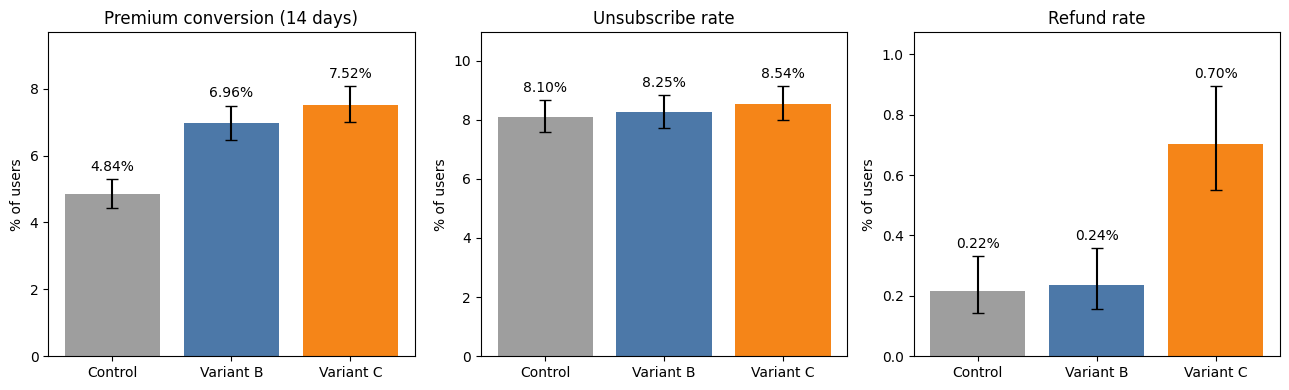

In [10]:
# Chart 1: conversion and guardrails by variant (95% CI)
metrics = {"converted_14d": "Premium conversion (14 days)",
           "unsub_14d": "Unsubscribe rate",
           "refunded_14d": "Refund rate"}
g = d.groupby("variant")
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (m, title) in zip(axes, metrics.items()):
    count = g[m].sum().reindex(order)
    n = g[m].size().reindex(order)
    rate = count / n
    lo, hi = proportion_confint(count.values, n.values, method="wilson")
    ax.bar([names[v] for v in order], rate * 100, color=colors,
           yerr=[(rate.values - lo) * 100, (hi - rate.values) * 100], capsize=4)
    for i, (r, h) in enumerate(zip(rate.values, hi)):
        ax.text(i, h * 100 + 0.02 * hi.max() * 100, f"{r * 100:.2f}%", ha="center", va="bottom")
    ax.set_title(title)
    ax.set_ylabel("% of users")
    ax.set_ylim(0, hi.max() * 100 * 1.2)
plt.tight_layout()
plt.show()

## 10. Chart: lift by segment
Both variants lift conversion overall (black). Segment intervals are wide and not adjusted for multiple comparisons: Android India is the clearest segment for C, and C does not help iOS USA.


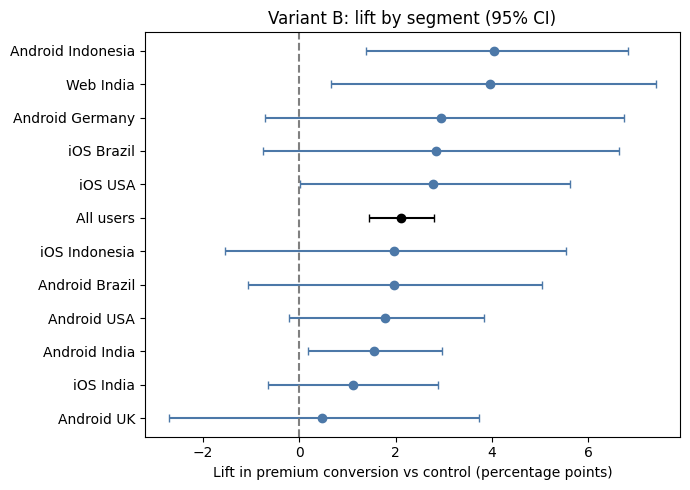

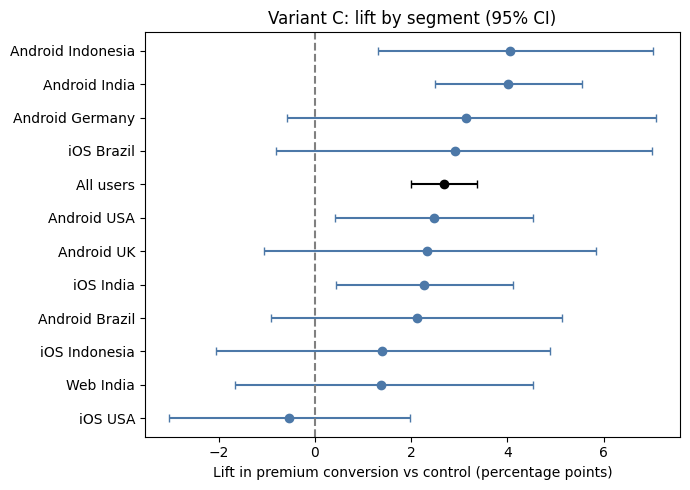

In [11]:
# Chart 2: lift vs control, overall and by segment
def lift_ci(df, arm, metric="converted_14d"):
    c = df[df.variant == "control"][metric]
    t = df[df.variant == arm][metric]
    lo, hi = confint_proportions_2indep(t.sum(), len(t), c.sum(), len(c), compare="diff")
    return (t.mean() - c.mean()) * 100, lo * 100, hi * 100

rows = []
for arm in ["variant_b", "variant_c"]:
    lift, lo, hi = lift_ci(d, arm)
    rows.append(dict(arm=arm, segment="All users", lift=lift, lo=lo, hi=hi))
    for (plat, ctry), gs in d.groupby(["platform", "country"]):
        if (gs.variant == "control").sum() >= 300:
            lift, lo, hi = lift_ci(gs, arm)
            rows.append(dict(arm=arm, segment=f"{plat} {ctry}", lift=lift, lo=lo, hi=hi))
seg = pd.DataFrame(rows)

for arm in ["variant_b", "variant_c"]:
    s = seg[seg.arm == arm].sort_values("lift").reset_index(drop=True)
    plt.figure(figsize=(7, 5))
    for i, r in s.iterrows():
        color = "black" if r.segment == "All users" else "#4c78a8"
        plt.errorbar(r.lift, i, xerr=[[r.lift - r.lo], [r.hi - r.lift]], fmt="o", color=color, capsize=3)
    plt.yticks(range(len(s)), s.segment)
    plt.axvline(0, color="grey", ls="--")
    plt.xlabel("Lift in premium conversion vs control (percentage points)")
    plt.title(f"{names[arm]}: lift by segment (95% CI)")
    plt.tight_layout()
    plt.show()


## Conclusion and limitations
Launch B broadly and test C in Android India with refund monitoring. Data is synthetic, and only users assigned by 14 Aug are included, so effects beyond 14 days and novelty effects are unknown. Segment results are exploratory.